# giFBA vs. dFBA: Flux Comparison

Reaction-level comparison of giFBA and dFBA fluxes. Reads the preprocessed `{name}_data/fluxes_{name}.pkl`, `hyperparams_{name}.csv` and `model_names_{name}.csv` written by `process_results.py`.

The flux frames hold only reactions active in at least one run, with rows and columns sorted identically for both methods. Hyperparameter-level analysis lives in `compare_hyperparameters.ipynb`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tol_colors as tol
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import benchmark_analysis_utils as bau

## 1. Pick the experiment

In [2]:
# The one line to edit when switching datasets.
ACTIVE_CONFIG_NAME = "N_orgs"  # "AH_BI" or "N_orgs"

config = bau.PRESETS[ACTIVE_CONFIG_NAME]
DATA_DIR = Path(f"{config.name}_data")
FIG_DIR = Path("dfba_comparison_figs")
FIG_DIR.mkdir(exist_ok=True)

missing = [
    p for p in (
        DATA_DIR / f"hyperparams_{config.name}.csv",
        DATA_DIR / f"model_names_{config.name}.csv",
        DATA_DIR / f"fluxes_{config.name}.pkl",
    )
    if not p.exists()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files {[str(p) for p in missing]}; "
        f"run `python process_results.py --config {config.name}` first."
    )
config

ExperimentConfig(name='N_orgs', results_dir='Benchmark_N_orgs', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load processed results

In [3]:
df = pd.read_csv(DATA_DIR / f"hyperparams_{config.name}.csv", index_col=0)
for col in bau.present(["rel_abund_list", "media"], df):
    df[col] = df[col].map(json.loads)

model_names = pd.read_csv(DATA_DIR / f"model_names_{config.name}.csv", index_col=0).iloc[:, 0].map(json.loads)

# Per-run equivalence metrics written by process_results.py (see
# bau.calc_equivalence_metrics for the raw sums).
EQ_COLS = [
    "Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns", "Sum_Abs_Flux",
    "gifba_abs_flux_sum", "dfba_abs_flux_sum",
    "MAE", "RPE",
]
eq_df = df[EQ_COLS].copy()

print(f"Loaded {len(df)} runs from {DATA_DIR}")
df.head()

Loaded 430 runs from N_orgs_data


,N_models,rel_abund,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,early_stop_window,early_stop_tol,...,Abs_Diff_Sum,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE,RPE,RPE_abs
run_id,,,,,,,,,,,,,,,,,,,,,
5906512_1,4,0.113436,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",7489,6790,19.179103,0.120450,BDF,20,1.000000e-07,...,13.906465,17.409310,133,7489,307.817473,153.894936,153.922536,0.001857,0.002325,0.002325
5912065_1,9,0.055533,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",15760,14262,11.768120,0.432876,BDF,20,1.000000e-07,...,35.322745,2.583354,4120,15760,269.127516,128.444733,140.682783,0.002241,0.000164,0.000164
5912065_10,9,0.050241,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",17718,15637,55.908102,0.792483,RK45,20,1.000000e-07,...,13.203588,117.162417,2297,17718,259.226305,130.900421,128.325884,0.000745,0.006613,0.006613
5912065_100,8,0.058220,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",13613,12040,22.051307,0.178865,BDF,20,1.000000e-07,...,12.179044,-58.555883,581,13613,221.611803,112.108170,109.503634,0.000895,-0.004301,0.004301
5912065_101,9,0.050154,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",11778,10806,20.092330,0.911163,RK45,20,1.000000e-07,...,61.380406,-36.528021,3934,11778,332.074038,155.931438,176.142600,0.005211,-0.003101,0.003101


In [4]:
fluxes = pd.read_pickle(DATA_DIR / f"fluxes_{config.name}.pkl")
gifba_fluxes_df = fluxes["gifba"]
dfba_fluxes_df = fluxes["dfba"]
flux_hist_counts = fluxes["flux_hist_counts"]
flux_hist_bin_edges = fluxes["flux_hist_bin_edges"]

assert gifba_fluxes_df.index.equals(df.index) and dfba_fluxes_df.index.equals(df.index)
assert gifba_fluxes_df.columns.equals(dfba_fluxes_df.columns)

print(f"giFBA fluxes: {gifba_fluxes_df.shape}")
print(f" dFBA fluxes: {dfba_fluxes_df.shape}")
print("giFBA: \n", gifba_fluxes_df.iloc[:5, :5])
print("dFBA: \n", dfba_fluxes_df.iloc[:5, :5])

giFBA fluxes: (430, 27505)
 dFBA fluxes: (430, 27505)
giFBA: 
              12DGR180tex___0  12DGR180tex___1  12DGR180tex___2  \
5906512_1                0.0              0.0              0.0   
5912065_1                0.0              0.0              0.0   
5912065_10               0.0              0.0              0.0   
5912065_100              0.0              0.0              0.0   
5912065_101              0.0              0.0              0.0   

             12DGR180tex___3  12DGR180tex___4  
5906512_1                0.0              0.0  
5912065_1                0.0              0.0  
5912065_10               0.0              0.0  
5912065_100              0.0              0.0  
5912065_101              0.0              0.0  
dFBA: 
              12DGR180tex___0  12DGR180tex___1  12DGR180tex___2  \
5906512_1                0.0              0.0              0.0   
5912065_1                0.0              0.0              0.0   
5912065_10               0.0              0.0 

## 3. Flux magnitude histogram

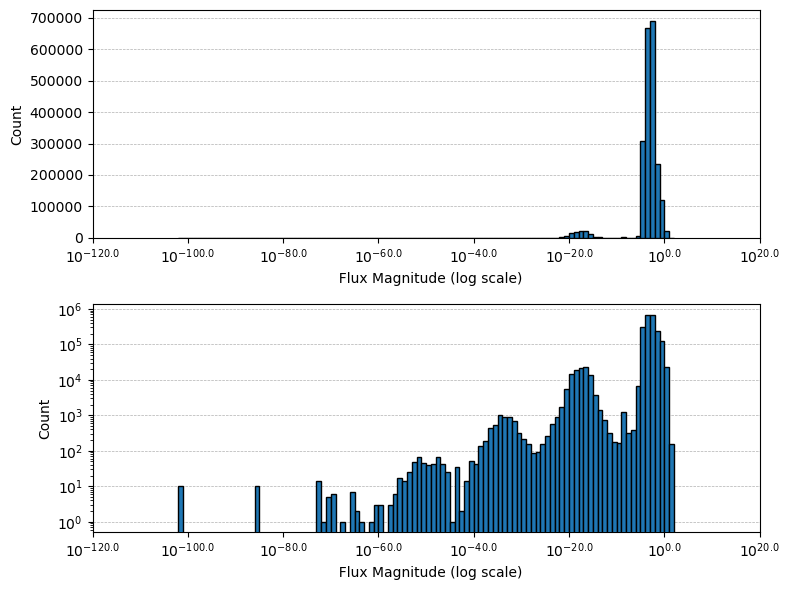

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
for ax, is_counts_log_scale in zip(axs, [False, True]):
    ax.bar(flux_hist_bin_edges[:-1], flux_hist_counts, width=1, align="edge", edgecolor="black", zorder=3)
    ax.set_xlabel("  Flux Magnitude (log scale)")
    if is_counts_log_scale:
        ax.set_yscale("log")
    ax.set_ylabel("Count")
    x_ticks = ax.get_xticks()
    ax.set_xticks(x_ticks)
    ax.set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
    ax.grid(axis="y", linestyle="--", linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(FIG_DIR / f"flux_magnitude_histogram_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 4. Filter out zero-growth and single-organism runs

In [11]:
times = df["dfba_termination_t"]
print(sum(times == 100), "out of", len(times), "simulations terminated without convergence")

zero_error_mask = (eq_df["MAE"] == 0) & (eq_df["RPE"] == 0)
print(sum(zero_error_mask), "out of", len(zero_error_mask), "simulations have 0 error")
zero_growth_mask = eq_df["Sum_Abs_Flux"] == 0
print(sum(zero_growth_mask), "out of", len(zero_growth_mask), "simulations have 0 growth")
singleton_mask = df["N_models"] == 1
print(sum(singleton_mask), "out of", len(singleton_mask), "simulations have N_models == 1")

filter_mask = ~zero_growth_mask & ~singleton_mask
eq_df_filtered = eq_df[filter_mask]

349 out of 430 simulations terminated without convergence
12 out of 430 simulations have 0 error
7 out of 430 simulations have 0 growth
47 out of 430 simulations have N_models == 1


## 5. 3D efficiency scatter + best/worst-example flux comparison

In [12]:
df_filtered = df[filter_mask]

X_data = df_filtered["dfba_pfba_calls"].values
X_lab = "# dFBA pFBA Calls"
X_scale = "log"

if config.name == "AH_BI":
    Y_data = df_filtered["vmax"].values
    Y_lab = "Vmax"
    Y_scale = "log"
    yvar = "vmax"
else:
    Y_data = df_filtered["gifba_pfba_calls"].values
    Y_lab = "# giFBA pFBA Calls"
    Y_scale = "log"
    yvar = "log-pfba-ratio"

Z_data = eq_df_filtered["MAE"].values
Z_lab = "MAE"
Z_scale = "linear"

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "scene"}, {"type": "xy"}, {"type": "xy"}]],
    subplot_titles=(
        "",
        "Best MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE"].min()),
        "Worst MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE"].max()),
    ),
)

for solver, color in bau.SOLVER_COLORS.items():
    solver_mask = (df_filtered["solver_method"] == solver).to_numpy()
    fig.add_trace(
        go.Scatter3d(
            x=X_data[solver_mask], y=Y_data[solver_mask], z=Z_data[solver_mask],
            mode="markers", name=solver,
            marker=dict(size=3, color=color, opacity=0.8),
            legend="legend",
        ),
        row=1, col=1,
    )

best_idx = eq_df_filtered["MAE"].idxmin()
worst_idx = eq_df_filtered["MAE"].idxmax()

gifba_best = gifba_fluxes_df.loc[best_idx]
dfba_best = dfba_fluxes_df.loc[best_idx].reindex(gifba_best.index)
best_color_map = bau.build_org_color_map(gifba_best.index.map(bau.get_org_index), plt.cm.Accent)
best_bounds = bau.add_flux_traces(fig, gifba_best, dfba_best, model_names.get(best_idx), best_color_map, "legend2", 2)

gifba_worst = gifba_fluxes_df.loc[worst_idx]
dfba_worst = dfba_fluxes_df.loc[worst_idx].reindex(gifba_worst.index)
worst_color_map = bau.build_org_color_map(gifba_worst.index.map(bau.get_org_index), plt.cm.Accent)
worst_bounds = bau.add_flux_traces(fig, gifba_worst, dfba_worst, model_names.get(worst_idx), worst_color_map, "legend3", 3)

camera_zoom = 2.0
fig.update_layout(
    scene=dict(
        xaxis_title=X_lab,
        yaxis_title=Y_lab,
        zaxis_title=Z_lab,
        xaxis=dict(type=X_scale, showgrid=True, zeroline=True, showticklabels=True),
        yaxis=dict(type=Y_scale, showgrid=True, zeroline=True, showticklabels=True),
        zaxis=dict(type=Z_scale, showgrid=True, zeroline=True, showticklabels=True),
        camera=dict(eye=dict(x=camera_zoom, y=camera_zoom, z=camera_zoom))
    ),
    height=600,
    showlegend=True,
    template="simple_white",
    legend=dict(
        title=dict(text="dFBA Solver"),
        orientation="v", x=0.15, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend2=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.50, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend3=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.85, y=-0.12, xanchor="center", yanchor="top",
    )
)

fig.show()
fig.write_html(FIG_DIR / f"3d_scatter_efficiency_{yvar}_mae_{config.name}.html")

## 6. Hyperparameters of the best/worst runs

In [13]:
param_cols = bau.present(
    ["vmax", "km", "rel_abund", "y0_factor", "y0_offset", "solver_method",
     "early_stop_window", "early_stop_tol", "gifba_iter_converged",
     "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls", "dfba_solve_time", "gifba_solve_time",
     "log10_time_ratio", "log10_pfba_call_ratio", "MAE", "RPE"],
    df,
)
print(pd.DataFrame({
    "Best Run": df.loc[best_idx, param_cols],
    "Worst Run": df.loc[worst_idx, param_cols],
}).to_string() )


                         Best Run   Worst Run
vmax                    24.770764    11.49757
km                       0.642807    0.890215
rel_abund                0.169825     0.05301
solver_method                 BDF         BDF
early_stop_window              20          20
early_stop_tol                0.0         0.0
gifba_iter_converged          3.0         4.0
gifba_periodicity             1.0         1.0
dfba_pfba_calls              2320        5148
gifba_pfba_calls             24.0       100.0
dfba_solve_time        173.122677  311.337076
gifba_solve_time        24.025289   31.672565
log10_time_ratio         0.857685    0.992548
log10_pfba_call_ratio    1.985277    1.711639
MAE                      0.000008    0.050104
RPE                      0.020537    0.000668


## 7. Per-reaction absolute difference for a single run

In [14]:
RUN_ID = best_idx

abs_diff = (gifba_fluxes_df.loc[RUN_ID] - dfba_fluxes_df.loc[RUN_ID]).abs()
factor = (gifba_fluxes_df.loc[RUN_ID] / dfba_fluxes_df.loc[RUN_ID]).astype("float64")
run_comparison = pd.DataFrame({
    "gifba": gifba_fluxes_df.loc[RUN_ID],
    "dfba": dfba_fluxes_df.loc[RUN_ID],
    "abs_diff": abs_diff,
    "factor": factor
})
run_comparison["organism"] = [
    bau.get_org_label(model_names.get(RUN_ID), bau.get_org_index(c)) for c in run_comparison.index
]

print(f"Run {RUN_ID}: MAE = {df.loc[RUN_ID, 'MAE']:.3e}")
run_comparison.sort_values("abs_diff", ascending=False).head(20)

Run 5912065_72: MAE = 8.323e-06


,gifba,dfba,abs_diff,factor,organism
GAPD___1,0.372386,0.367034,0.005352,1.014581,Salmonella_enterica_subsp_enterica_serovar_Ent...
GAPD_NADP___1,0.123944,0.129296,0.005352,0.958608,Salmonella_enterica_subsp_enterica_serovar_Ent...
IPDPS___1,0.005352,0.0,0.005352,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
IPDPS2___1,0.0,0.005352,0.005352,0.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
FRD2___1,0.000726,0.0,0.000726,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
DHORD5___1,0.000726,0.0,0.000726,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
DHORD2___1,0.0,0.000726,0.000726,0.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
FRD7___1,0.007771,0.008497,0.000726,0.914538,Salmonella_enterica_subsp_enterica_serovar_Ent...
L_LACt2rpp___1,-0.32584,-0.32584,0.0,1.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
LDH_L___1,-0.32584,-0.32584,0.0,1.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
